In [1]:
import matplotlib.pyplot as plt
import numpy as np
from nltk.corpus import abc

import word2vec as w2v

In [2]:
# Import corpus as a raw string
# ABC science is a collection of Australian Broadcasting Corporation science news articles

corpus = abc.raw('science.txt')
assert isinstance(corpus, str)

print(corpus[:350])

Cystic fibrosis affects 30,000 children and young adults in the US alone
Inhaling the mists of salt water can reduce the pus and infection that fills the airways of cystic fibrosis sufferers, although side effects include a nasty coughing fit and a harsh taste. 
That's the conclusion of two studies published in this week's issue of The New Englan


In [3]:
# Split corpus into sentences and tokenize
sentences = w2v.split_sentences(corpus)
tokenized_sentences = [w2v.tokenize(s) for s in sentences]

# Split tokenized sentences into train, validation, and test sets
train_sentences, val_sentences, test_sentences = w2v.random_split(
    tokenized_sentences, (0.70, 0.85), seed=42
)
# Build vocab from train sentences
word_to_id, id_to_word, word_counts = w2v.build_vocab(train_sentences, min_count=5)

# How much of the validation and test text does our training vocabulary cover?
# Word occurrences count every appearance of a word
# Unique words count each distinct word once
splits = [('Validation', val_sentences), ('Test', test_sentences)]

print(f'Training vocabulary: {len(word_to_id):,} words\n')
print(f'{"Split":<12} {"Word occurrences":>16} {"Unique words":>14}')

for split_name, split in splits:
    token_coverage, type_coverage = w2v.vocab_coverage(split, word_to_id)
    print(f'{split_name:<12} {token_coverage:>16.2%} {type_coverage:>14.2%}')

Training vocabulary: 5,359 words

Split        Word occurrences   Unique words
Validation             89.05%         48.72%
Test                   89.66%         49.80%


In [4]:
# Use the same vocab to generate pairs for all three sets
WINDOW_SIZE = 2

train_pairs = w2v.generate_pairs(train_sentences, word_to_id, WINDOW_SIZE)
val_pairs = w2v.generate_pairs(val_sentences, word_to_id, WINDOW_SIZE)
test_pairs = w2v.generate_pairs(test_sentences, word_to_id, WINDOW_SIZE)

print(f'Training pairs: {len(train_pairs)}')
print(f'Val pairs: {len(val_pairs)}')
print(f'Test pairs: {len(test_pairs)}')

Training pairs: 788518
Val pairs: 161286
Test pairs: 164442


In [5]:
LEARNING_RATE = 0.01
EMBEDDING_DIM = 10
EPOCHS = 3
RESTORE_BEST_WEIGHTS = False

model = w2v.Word2Vec(word_to_id, id_to_word, EMBEDDING_DIM, LEARNING_RATE, seed=42)

train_loss_history, val_loss_history = model.train(
    train_pairs, val_pairs, epochs=EPOCHS, restore_best_weights=RESTORE_BEST_WEIGHTS
)

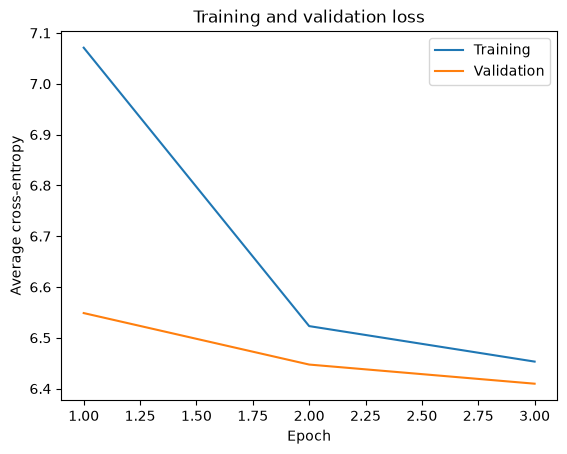

In [6]:
epochs = range(1, len(train_loss_history) + 1)

plt.plot(epochs, train_loss_history, label='Training')
plt.plot(epochs, val_loss_history, label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Average cross-entropy')
plt.title('Training and validation loss')
plt.legend()
plt.show()